# Feature Engineering & Feature Selection — Predição de Carga Alta (EVCOMX)

Segue duas fontes:
- **Aula de Feature Selection do bootcamp** (slides citados como "slide N");
- **Guia de Feature Engineering & Feature Selection da EVCOMX** (citado como "Guia §N").

Roteiro (slide 33 + Guia §11):

| Etapa | Seção |
|---|---|
| Unidade de análise e split 70/15/15 temporal | 1 |
| Feature engineering: massa/volume, composição, ordem/ciclos, tempo, interações, contexto | 2 |
| Seleção na mão: IDs, constantes, "colas" | 3 |
| Filtro: correlação, Mann-Whitney, informação mútua | 4 |
| Multicolinearidade: correlação > 0,90 e VIF < 10 | 5 |
| Ponto de partida: modelo com todas as colunas | 6 |
| Embedded: L1, Elastic Net, importância e permutação | 7 |
| Wrapper: RFE com validação cruzada | 8 |
| Colunas de mentira (Boruta) | 9 |
| Votação, estabilidade e curva desempenho × nº de features | 10 |
| Comparação dos conjuntos na validação (inclui o baseline mínimo "só volume") | 11 |
| Features sugeridas pelo Guia de Modelagem, testadas à parte | 11b |
| Conferência no teste, uma única vez | 12 |
| Mudança de regime em maio/2026 | 13 |
| Respostas às perguntas do Guia §1.3 | 14 |
| Arquivos para a modelagem e tabela das features finais | 15 |

**Rode antes o `EDA/transforma_dataset.py`**: a feature selection parte do `EDA/base.csv`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr, mannwhitneyu, binomtest

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif, RFECV, RFE
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, accuracy_score, confusion_matrix)

SEED = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, VERMELHO, CINZA, LARANJA, VERDE = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e", "#4a8c4a"

## 0. Ler a base limpa da EDA

A feature selection **não refaz a limpeza**: lê o `EDA/base.csv` gerado pelo
`EDA/transforma_dataset.py`. Decisões de limpeza que já vêm aplicadas:
- duplicatas 100% iguais removidas;
- **camadas abaixo de 2.000 kg removidas, peso zero incluído** (EVCOMX: peso zero = o gancho
  não pegou o material, a camada nunca entrou no cestão; e, por e-mail, camadas de 10 ou 100 kg
  também podem ser desconsideradas, "dificilmente temos camadas com menos de 2000kg");
- hora das 152 camadas sem horário estimada pela corrida;
- propriedades de RECC/RECG estimadas (pesquisa do Lucas);
- densidade e rendimento como número.

A variável resposta vem de `original_dataset/` (somente leitura).

In [2]:
# Acha a raiz do repositório subindo pastas (funciona rodando de feature_selection/ ou da raiz)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "EDA").is_dir() and (p / "original_dataset").is_dir())
PASTA_EDA, PASTA_BRUTOS = RAIZ / "EDA", RAIZ / "original_dataset"
PASTA_SAIDA = RAIZ / "feature_selection"
PASTA_GRAF = PASTA_SAIDA / "graficos"
PASTA_GRAF.mkdir(exist_ok=True)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(PASTA_GRAF / f"{nome}.png", dpi=130, bbox_inches="tight")
    plt.show()

arq_base, arq_pipeline = PASTA_EDA / "base.csv", PASTA_EDA / "transforma_dataset.py"
assert arq_base.exists(), "EDA/base.csv não existe: rode o EDA/transforma_dataset.py primeiro!"
if arq_pipeline.exists() and arq_pipeline.stat().st_mtime > arq_base.stat().st_mtime:
    print("ATENÇÃO: transforma_dataset.py foi alterado depois do base.csv ser gerado.\n"
          "         Rode o pipeline de novo para usar a limpeza atual.")

base = pd.read_csv(arq_base)
resposta = pd.read_csv(PASTA_BRUTOS / "VariavelResposta.csv")
dataset_eda = pd.read_csv(PASTA_EDA / "dataset_modelagem.csv")   # só para conferir que batemos com a EDA

base["dt_hora_consumo"] = pd.to_datetime(base["dt_hora_consumo"], utc=True, format="ISO8601")
base["cd_codigo_material"] = base["cd_codigo_material"].astype(str)
cam = base[base.nu_carregamento.isin([1, 2])].rename(columns={
    "Energia Elétrica": "energia_kwh_t", "Densidade t/m3": "densidade_t_m3",
    "Rendimento Metálico %": "rendimento"}).copy()

print("Raiz do projeto:", RAIZ)
print("Camadas dos cestões 1 e 2:", cam.shape)
print("Camadas abaixo de 2.000 kg (deve ser 0):", int((cam.qt_peso_carregamento < 2000).sum()))
print("Sem densidade / sem classe:", cam.densidade_t_m3.isna().sum(), "/", cam.tp_material.isna().sum())

Raiz do projeto: /tmp/claude-0/-home-claude/97fa3141-49e4-553d-82de-5cc48c814ff0/scratchpad/novo
Camadas dos cestões 1 e 2: (36633, 19)
Camadas abaixo de 2.000 kg (deve ser 0): 0
Sem densidade / sem classe: 0 / 0


## 1. Unidade de análise e split (Guia §2)

**Unidade: o carregamento (cestão 1 ou 2).** Justificativa:
- é a pergunta operacional: "este cestão vai dar carga alta?" — dá para agir no cestão antes
  de despejá-lo;
- o alvo já vem separado por cestão (`is_carga_alta_carregamento_1/2`);
- dobra o número de exemplos (~3.500 cestões contra ~1.800 corridas);
- o cestão 2 pode usar o que se sabe do cestão 1 (seção 2.5).

O carregamento 3 (gusa líquido) não entra: nunca gera carga alta.

**Split 70/15/15, temporal, definido pelo professor.** As 70% corridas mais antigas são o
treino, as 15% seguintes a validação e as 15% mais recentes o teste. Os dois cestões da mesma
corrida ficam sempre do mesmo lado. Split aleatório vazaria informação do futuro (Guia §2.2).
- **Treino:** onde todos os métodos de seleção rodam.
- **Validação:** onde escolhemos quantas features ficam e o limiar de decisão.
- **Teste:** usado uma única vez, no final (slide 30).

In [3]:
chave = ["cd_corrida", "nu_carregamento"]
inicio_cestao = cam.groupby(chave)["dt_hora_consumo"].min()
inicio_corrida = inicio_cestao.groupby(level=0).min().sort_values()
n_corr = len(inicio_corrida)
corte_val = inicio_corrida.iloc[int(n_corr * 0.70)]
corte_teste = inicio_corrida.iloc[int(n_corr * 0.85)]
conjunto_corrida = pd.Series(
    np.select([inicio_corrida < corte_val, inicio_corrida < corte_teste], ["treino", "validacao"], "teste"),
    index=inicio_corrida.index)
print(f"Validação a partir de {corte_val.tz_convert('America/Sao_Paulo'):%d/%m/%Y}, "
      f"teste a partir de {corte_teste.tz_convert('America/Sao_Paulo'):%d/%m/%Y}")
print(conjunto_corrida.value_counts())

Validação a partir de 25/04/2026, teste a partir de 24/06/2026
treino       1259
validacao     270
teste         270
Name: count, dtype: int64


## 2. Feature engineering

Transformar várias linhas de camadas em **uma linha por cestão** (Guia §1.2). As features
estão em 5 grupos, com a intuição física de cada uma:

| Grupo | Features | Intuição |
|---|---|---|
| 2.1 Massa e volume (Guia §3) | `peso_t_total`, `volume_m3_total`, `densidade_media`, `razao_vol_peso`, peso e proporção por classe, `rendimento_medio`, `energia_estimada_mwh`, `energia_por_ton` | quanto material e quanto espaço ele ocupa |
| 2.2 Composição (Guia §4) | `num_materiais`, `num_camadas`, `num_baias`, `hhi_materiais`, `prop_<material>` | o quê e quanta variedade |
| 2.3 Ordem, ciclos e posição (Guia §5) | `n_ciclos`, blocos, `fundo_*`, `topo_*`, peso e leve nos 30% de cima/baixo, `pos_media_pesado`, `violacao_regra` | **a sequência leve → pesado → misto → leve se repete várias vezes no cestão** (correção da EVCOMX) |
| 2.4 Tempo (Guia §5.3) | `tempo_montagem_min`, `intervalo_medio_min`, `turno_A/B`, `hora`, `dia_semana`, `fim_de_semana` | ritmo e equipe |
| 2.5 Interações e contexto (Guia §6) | `vol_x_prop_leve`, `peso_x_hhi`, `peso_por_ciclo_t`, `peso_leve_topo_t`, dados do cestão 1 no cestão 2, taxa recente de carga alta | combinações com sentido físico e "estado do forno" |

In [4]:
cam = cam.sort_values(chave + ["nu_camada"]).reset_index(drop=True)
g = cam.groupby(chave)
cam["ordem"] = g.cumcount()
cam["n_cam"] = g["nu_camada"].transform("size")
cam["pos_rel"] = cam["ordem"] / (cam["n_cam"] - 1).clip(lower=1)      # 0 = fundo, 1 = topo
feat = pd.DataFrame(index=inicio_cestao.index)

def por_cestao(serie, preencher=0):
    """Reindexa um resultado agregado por cestão para todas as linhas de `feat`."""
    return serie.reindex(feat.index).fillna(preencher)

### 2.1 Massa e volume (Guia §3)

In [5]:
feat["peso_t_total"] = g["peso_t"].sum()
feat["volume_m3_total"] = g["volume_m3"].sum()
feat["ocupacao_cestao"] = feat["volume_m3_total"] / 78                  # capacidade: 78 m³
feat["densidade_media"] = feat["peso_t_total"] / feat["volume_m3_total"]
feat["razao_vol_peso"] = feat["volume_m3_total"] / feat["peso_t_total"]  # Guia pergunta: é 1/densidade? (sim)
feat["peso_max_camada_t"] = g["peso_t"].max()
feat["peso_medio_camada_t"] = g["peso_t"].mean()
for classe, k in [("Leve", "leve"), ("Misto", "misto"), ("Pesado", "pesado")]:
    m = cam["tp_material"] == classe
    feat[f"peso_{k}"] = por_cestao(cam[m].groupby(chave)["peso_t"].sum())
    feat[f"vol_{k}_m3"] = por_cestao(cam[m].groupby(chave)["volume_m3"].sum())
    feat[f"prop_peso_{k}"] = feat[f"peso_{k}"] / feat["peso_t_total"]
    feat[f"prop_vol_{k}"] = feat[f"vol_{k}_m3"] / feat["volume_m3_total"]
feat = feat.rename(columns={"prop_peso_leve": "prop_leve"})             # mesmo nome da EDA

feat["rendimento_medio"] = (cam["rendimento"] * cam["peso_t"]).groupby([cam.cd_corrida, cam.nu_carregamento]).sum() / feat["peso_t_total"]
feat["energia_estimada_mwh"] = (cam["energia_kwh_t"] * cam["peso_t"]).groupby([cam.cd_corrida, cam.nu_carregamento]).sum() / 1000
feat["energia_por_ton"] = feat["energia_estimada_mwh"] * 1000 / feat["peso_t_total"]   # kWh/t

### 2.2 Composição (Guia §4)

Proporção **em peso** de cada material. Materiais presentes em menos de 5% dos cestões
viram `prop_outros`, para evitar colunas quase sempre zero (Guia §4.3). A frequência é
calculada só com o treino (o critério é escolhido sem olhar validação/teste).

In [6]:
feat["num_camadas"] = g["nu_camada"].nunique()
feat["num_materiais"] = g["cd_codigo_material"].nunique()
feat["num_baias"] = g["cd_baia"].nunique()

peso_mat = cam.pivot_table(index=chave, columns="cd_codigo_material", values="peso_t",
                           aggfunc="sum", fill_value=0).reindex(feat.index).fillna(0)
prop_mat = peso_mat.div(peso_mat.sum(axis=1), axis=0)
feat["hhi_materiais"] = (prop_mat ** 2).sum(axis=1)

no_treino = feat.index.get_level_values("cd_corrida").map(conjunto_corrida) == "treino"
freq_mat = (peso_mat[no_treino] > 0).mean()
comuns = freq_mat[freq_mat >= 0.05].index
print("Materiais com coluna própria (>= 5% dos cestões do treino):", list(comuns))
print("Agrupados em 'outros':", list(freq_mat[freq_mat < 0.05].index))
for mat in comuns:
    feat[f"prop_{mat}"] = prop_mat[mat]
feat["prop_outros"] = prop_mat.drop(columns=comuns).sum(axis=1)

Materiais com coluna própria (>= 5% dos cestões do treino): ['118441', '194032', 'CAFO', 'CAVA', 'ESPR', 'ESPS', 'FOFO', 'GUSS', 'MISB', 'MISM', 'OXIC', 'PACB', 'PAEP', 'RECA', 'RETL', 'SHRE', 'SUGU']
Agrupados em 'outros': ['ESBS', 'MARP', 'PAEB', 'RECC', 'RECG']


### 2.3 Ordem, ciclos e posição das camadas (Guia §5)

**Correção da EVCOMX:** a ordem leve → pesado → misto → leve **se repete em vários ciclos
dentro do mesmo cestão**. Camadas seguidas da mesma classe formam um **bloco**; cada ciclo tem
um bloco de pesado, então `n_ciclos` = nº de blocos de pesado. Nos dados o ciclo aparece tanto
como L→P→M quanto L→M→P; `n_ciclos_LPM` conta só os que seguem exatamente L→P→M.

Posição: os 30% de camadas de baixo e de cima (Guia §5.1) e a posição média dos pesados
ponderada pelo peso. `violacao_regra` = pesado na primeira ou na última camada.

In [7]:
cam["novo_bloco"] = cam["tp_material"] != cam.groupby(chave)["tp_material"].shift()
cam["id_bloco"] = cam.groupby(chave)["novo_bloco"].cumsum()
blocos = (cam.groupby(chave + ["id_bloco"])
          .agg(classe=("tp_material", "first"), peso_t=("peso_t", "sum"), volume_m3=("volume_m3", "sum"))
          .reset_index())
feat["n_blocos"] = blocos.groupby(chave).size()
for classe, k in [("Leve", "leve"), ("Misto", "misto"), ("Pesado", "pesado")]:
    bc = blocos[blocos["classe"] == classe].groupby(chave)
    feat[f"n_blocos_{k}"] = por_cestao(bc.size())
    feat[f"max_bloco_{k}_m3"] = por_cestao(bc["volume_m3"].max())
feat["n_ciclos"] = feat.pop("n_blocos_pesado")
sigla = blocos["classe"].map({"Leve": "L", "Pesado": "P", "Misto": "M"})
seq_blocos = sigla.groupby([blocos.cd_corrida, blocos.nu_carregamento]).agg("".join)
feat["n_ciclos_LPM"] = seq_blocos.str.count("(?=LPM)")

primeira = g.head(1).set_index(chave)["tp_material"]
ultima = g.tail(1).set_index(chave)["tp_material"]
for classe, k in [("Leve", "leve"), ("Misto", "misto"), ("Pesado", "pesado")]:
    feat[f"fundo_{k}"] = (primeira == classe).astype(int)
    feat[f"topo_{k}"] = (ultima == classe).astype(int)
feat["violacao_regra"] = ((primeira == "Pesado") | (ultima == "Pesado")).astype(int)

topo30, base30 = cam["pos_rel"] >= 0.7, cam["pos_rel"] <= 0.3
eh_leve, eh_pesado = cam["tp_material"] == "Leve", cam["tp_material"] == "Pesado"
feat["peso_topo_30pct_t"] = por_cestao(cam[topo30].groupby(chave)["peso_t"].sum())
feat["peso_base_30pct_t"] = por_cestao(cam[base30].groupby(chave)["peso_t"].sum())
feat["peso_leve_topo_t"] = por_cestao(cam[topo30 & eh_leve].groupby(chave)["peso_t"].sum())
feat["prop_leve_topo"] = feat["peso_leve_topo_t"] / feat["peso_topo_30pct_t"]
feat["prop_leve_base"] = por_cestao(cam[base30 & eh_leve].groupby(chave)["peso_t"].sum()) / feat["peso_base_30pct_t"]

def pos_ponderada(mascara):
    d = cam[mascara]
    return (d["pos_rel"] * d["peso_t"]).groupby([d.cd_corrida, d.nu_carregamento]).sum() / d.groupby(chave)["peso_t"].sum()
feat["pos_media_pesado"] = pos_ponderada(eh_pesado).reindex(feat.index)   # NaN se não há pesado
feat["pos_media_leve"] = pos_ponderada(eh_leve).reindex(feat.index)

### 2.4 Tempo (Guia §5.3)

Turno no padrão da EVCOMX: A (06–14h), B (14–22h), C (22–06h, a referência).

A data/hora em si (`inicio`) **não é feature**: com split temporal, todo valor da validação e
do teste é maior que qualquer valor do treino, e o modelo só aprenderia "em que época estamos",
o que não serve para o futuro. Ela fica no dataset só como metadado. Hora, dia da semana e
turno se repetem e podem entrar.

In [8]:
ini_local = inicio_cestao.dt.tz_convert("America/Sao_Paulo")
fim_local = g["dt_hora_consumo"].max().dt.tz_convert("America/Sao_Paulo")
feat["inicio"] = ini_local                                               # metadado, não é feature
feat["tempo_montagem_min"] = (fim_local - ini_local).dt.total_seconds() / 60
feat["intervalo_medio_min"] = feat["tempo_montagem_min"] / (feat["num_camadas"] - 1).replace(0, np.nan)
feat["hora"] = ini_local.dt.hour
feat["turno_A"] = feat["hora"].between(6, 13).astype(int)
feat["turno_B"] = feat["hora"].between(14, 21).astype(int)
feat["dia_semana"] = ini_local.dt.dayofweek
feat["fim_de_semana"] = (feat["dia_semana"] >= 5).astype(int)

### 2.5 Interações e contexto (Guia §6)

**Interações** (poucas e com sentido físico, Guia §6.1):
- `vol_x_prop_leve`: volume alto com muito leve;
- `peso_x_hhi`: muito peso concentrado em poucos materiais;
- `peso_por_ciclo_t`: quanto material entra por ciclo (ciclos "grossos" = camadas mal intercaladas).

**Contexto do cestão 1 para o cestão 2** (Guia §6.2): quando o cestão 2 é despejado, o forno já
contém o cestão 1, então os dados do cestão 1 são informação disponível. No cestão 1 essas
colunas valem 0 e `eh_cestao_2` distingue os casos.

**Histórico recente:** taxa de carga alta das últimas N corridas, com `shift(1)` para não usar a
corrida atual (sem vazamento).

**`carga_alta_c1` (se o cestão 1 teve carga alta) fica de fora por enquanto:** o Guia pede para
discutir o timing. Testamos seu efeito à parte na seção 11.

In [9]:
feat["vol_x_prop_leve"] = feat["volume_m3_total"] * feat["prop_leve"]
feat["peso_x_hhi"] = feat["peso_t_total"] * feat["hhi_materiais"]
feat["peso_por_ciclo_t"] = feat["peso_t_total"] / feat["n_ciclos"].clip(lower=1)

feat = feat.reset_index()
feat["eh_cestao_2"] = (feat["nu_carregamento"] == 2).astype(int)
c1 = feat[feat.nu_carregamento == 1].set_index("cd_corrida")
eh2 = feat["eh_cestao_2"] == 1
feat["volume_c1_m3"] = np.where(eh2, feat["cd_corrida"].map(c1["volume_m3_total"]), 0)
feat["peso_c1_t"] = np.where(eh2, feat["cd_corrida"].map(c1["peso_t_total"]), 0)
feat["vol_acumulado_m3"] = feat["volume_m3_total"] + feat["volume_c1_m3"].fillna(0)
feat["delta_peso_12_t"] = np.where(eh2, feat["peso_t_total"] - feat["peso_c1_t"], 0)
mat_c1 = cam[cam.nu_carregamento == 1].groupby("cd_corrida")["cd_codigo_material"].agg(frozenset)
mat_c2 = cam[cam.nu_carregamento == 2].groupby("cd_corrida")["cd_codigo_material"].agg(frozenset)
feat["mudou_composicao"] = np.where(eh2, (feat["cd_corrida"].map(mat_c1) != feat["cd_corrida"].map(mat_c2)).astype(int), 0)

# histórico: taxa de carga alta das N corridas anteriores (ordem cronológica, shift(1))
hist = resposta[["cd_corrida", "is_carga_alta"]].assign(t=lambda d: d.cd_corrida.map(inicio_corrida)).sort_values("t")
for n in [5, 10, 20]:
    hist[f"taxa_ca_ult{n}"] = hist["is_carga_alta"].shift(1).rolling(n, min_periods=1).mean()
for n in [5, 10, 20]:
    feat[f"taxa_ca_ult{n}"] = feat["cd_corrida"].map(hist.set_index("cd_corrida")[f"taxa_ca_ult{n}"])

# conferência: as 8 features que já existiam na EDA batem com o dataset_modelagem do grupo?
conf = feat.merge(dataset_eda, on=chave, suffixes=("", "_eda"))
for c in ["num_camadas", "num_materiais", "peso_leve", "peso_misto", "peso_pesado",
          "peso_t_total", "volume_m3_total", "prop_leve"]:
    print(f"{c:16s} diferença máxima para a EDA: {(conf[c] - conf[c + '_eda']).abs().max():.6f}")
print("Tabela de features:", feat.shape)

num_camadas      diferença máxima para a EDA: 0.000000
num_materiais    diferença máxima para a EDA: 0.000000
peso_leve        diferença máxima para a EDA: 0.000000
peso_misto       diferença máxima para a EDA: 0.000000
peso_pesado      diferença máxima para a EDA: 0.000000
peso_t_total     diferença máxima para a EDA: 0.000000
volume_m3_total  diferença máxima para a EDA: 0.000000
prop_leve        diferença máxima para a EDA: 0.000000
Tabela de features: (3501, 88)


### Juntar com a variável resposta e com o split

In [10]:
alvo = pd.concat([
    resposta.assign(nu_carregamento=1.0, carga_alta=resposta.is_carga_alta_carregamento_1,
                    segundos_parada=resposta.qt_segundos_duracao_parada_carregamento_1),
    resposta.assign(nu_carregamento=2.0, carga_alta=resposta.is_carga_alta_carregamento_2,
                    segundos_parada=resposta.qt_segundos_duracao_parada_carregamento_2),
])[chave + ["carga_alta", "segundos_parada"]]
c1_alvo = alvo[alvo.nu_carregamento == 1].set_index("cd_corrida")["carga_alta"]

df = feat.merge(alvo, on=chave, how="inner")
df["conjunto"] = df["cd_corrida"].map(conjunto_corrida)
df["carga_alta_c1"] = np.where(df.eh_cestao_2 == 1, df["cd_corrida"].map(c1_alvo), 0)   # só para a seção 11
print("Cestões:", len(df), "| sem camadas do cestão 2 mas com carga alta nele (fora):",
      int(alvo[(alvo.nu_carregamento == 2) & (alvo.carga_alta == 1)]
          .merge(feat[chave], on=chave, how="left", indicator=True)["_merge"].eq("left_only").sum()))
print(df.groupby("conjunto").agg(cestoes=("carga_alta", "size"), taxa_carga_alta=("carga_alta", "mean"),
                                 de=("inicio", "min"), ate=("inicio", "max")).loc[["treino", "validacao", "teste"]])

treino = df[df.conjunto == "treino"].reset_index(drop=True)
valid = df[df.conjunto == "validacao"].reset_index(drop=True)
teste = df[df.conjunto == "teste"].reset_index(drop=True)

Cestões: 3501 | sem camadas do cestão 2 mas com carga alta nele (fora): 7
           cestoes  taxa_carga_alta                        de                       ate
conjunto                                                                               
treino        2473         0.158512 2025-08-14 20:17:11-03:00 2026-04-25 21:50:08-03:00
validacao      513         0.179337 2026-04-25 19:42:26-03:00 2026-06-27 14:08:12-03:00
teste          515         0.145631 2026-06-24 08:02:26-03:00 2026-08-04 02:36:01-03:00


## 3. Seleção na mão (slides 13–16)

Perguntas: faz sentido? Vou ter na hora de prever? É confiável? Repete outra? Tudo calculado
**só no treino**.

In [11]:
metadados = ["cd_corrida", "nu_carregamento", "carga_alta", "conjunto", "inicio", "carga_alta_c1"]
descartes = {
    "segundos_parada": "vazamento: a duração da parada só existe depois da carga alta",
}
candidatas = [c for c in df.columns if c not in metadados and c not in descartes]
for c in candidatas:
    moda = treino[c].value_counts(normalize=True, dropna=False).iloc[0]
    if treino[c].nunique(dropna=False) <= 1:
        descartes[c] = "constante"
    elif moda > 0.99:
        descartes[c] = f"quase constante ({moda:.1%} igual)"
    elif treino[c].isna().mean() > 0.5:
        descartes[c] = f"quase vazia ({treino[c].isna().mean():.0%} nulo)"
candidatas = [c for c in candidatas if c not in descartes]
print(pd.Series(descartes).to_string())
print(f"\nSobraram {len(candidatas)} candidatas")
print("Com vazios no treino (% ):", (treino[candidatas].isna().mean() * 100).loc[lambda s: s > 0].round(1).to_dict())

segundos_parada    vazamento: a duração da parada só existe depoi...
fundo_pesado                           quase constante (99.8% igual)

Sobraram 84 candidatas
Com vazios no treino (% ): {'pos_media_pesado': 2.2, 'pos_media_leve': 0.4, 'taxa_ca_ult5': 0.1, 'taxa_ca_ult10': 0.1, 'taxa_ca_ult20': 0.1}


## 4. Filtro (slides 18–21, Guia §7.1)

Cada coluna recebe uma nota sozinha:
- **correlação point-biserial** com o alvo (direção e força linear);
- **Mann-Whitney U**: a distribuição da feature é diferente entre cestões com e sem carga alta?
  Com ~70 testes, usamos a correção de Bonferroni (p × nº de testes < 0,05) para não "achar"
  diferença por sorte;
- **informação mútua**: enxerga relações curvas que a correlação perde (slide 20).

Voto do filtro: Mann-Whitney significativo (Bonferroni) **ou** entre as 10 maiores informações mútuas.

|corr| > 0,1: 34 | Mann-Whitney (Bonferroni) significativo: 42 | voto do filtro: 43
Correlação e Mann-Whitney discordam em: ['prop_vol_leve', 'intervalo_medio_min', 'prop_ESPS', 'dia_semana', 'prop_OXIC', 'fim_de_semana', 'prop_ESPR', 'turno_A']
                        corr  p_mannwhitney  p_bonferroni  info_mutua  voto_filtro
feature                                                                           
prop_peso_pesado     -0.3173            0.0           0.0      0.0621         True
razao_vol_peso        0.3069            0.0           0.0      0.0504         True
prop_vol_pesado      -0.3020            0.0           0.0      0.0572         True
densidade_media      -0.2954            0.0           0.0      0.0505         True
peso_por_ciclo_t      0.2922            0.0           0.0      0.0324         True
peso_pesado          -0.2889            0.0           0.0      0.0659         True
vol_pesado_m3        -0.2849            0.0           0.0      0.0629         True
taxa_ca

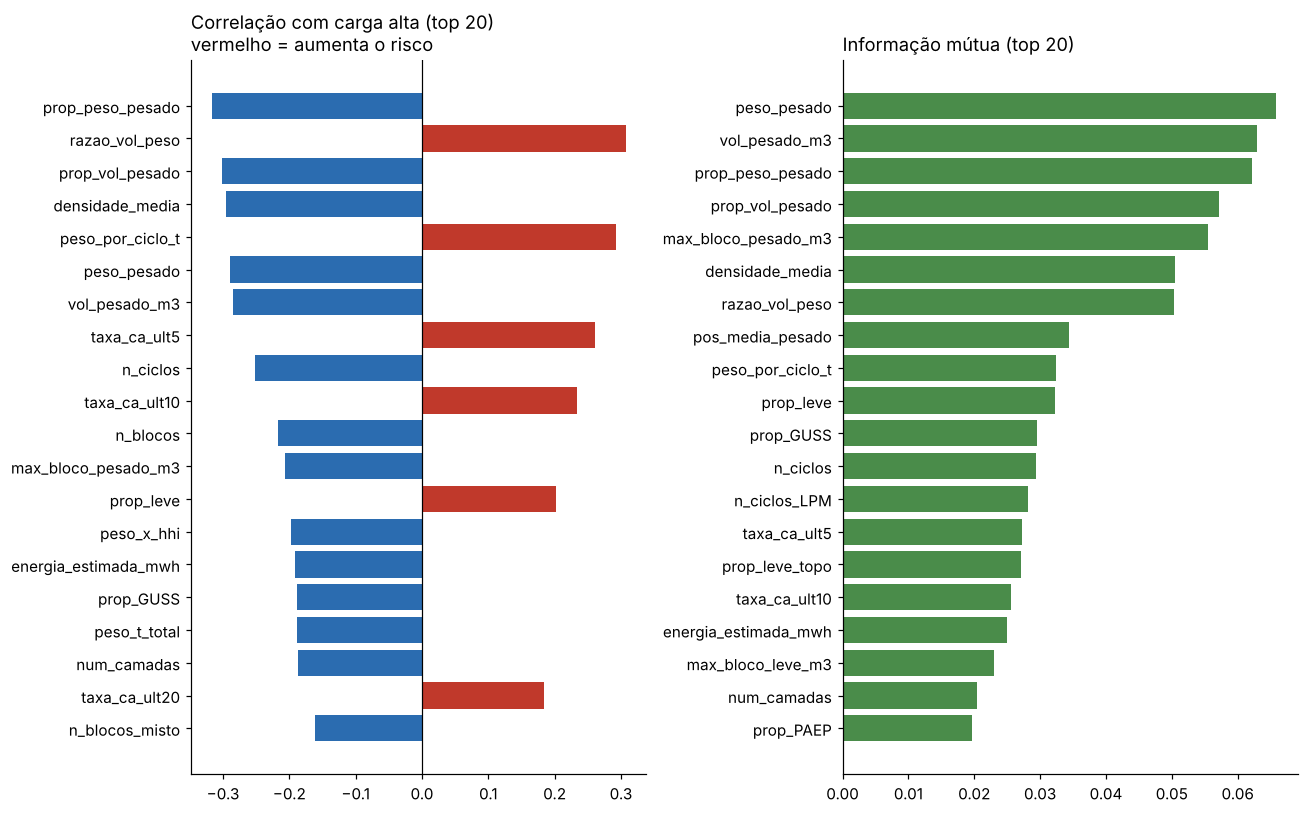

In [12]:
X_tr_full = treino[candidatas]
y_tr = treino["carga_alta"]
mediana_tr = X_tr_full.median()
filtro = []
for c in candidatas:
    x = X_tr_full[c].fillna(mediana_tr[c])
    r_, _ = pointbiserialr(y_tr, x)
    _, p_mw = mannwhitneyu(x[y_tr == 0], x[y_tr == 1])
    filtro.append((c, r_, p_mw))
filtro = pd.DataFrame(filtro, columns=["feature", "corr", "p_mannwhitney"]).set_index("feature")
filtro["p_bonferroni"] = (filtro["p_mannwhitney"] * len(candidatas)).clip(upper=1)
filtro["info_mutua"] = mutual_info_classif(X_tr_full.fillna(mediana_tr), y_tr, random_state=SEED)
top_mi = set(filtro["info_mutua"].nlargest(10).index)
filtro["voto_filtro"] = (filtro["p_bonferroni"] < 0.05) | filtro.index.isin(top_mi)
filtro = filtro.reindex(filtro["corr"].abs().sort_values(ascending=False).index)
print(f"|corr| > 0,1: {(filtro['corr'].abs() > 0.1).sum()} | Mann-Whitney (Bonferroni) significativo: "
      f"{(filtro['p_bonferroni'] < 0.05).sum()} | voto do filtro: {filtro['voto_filtro'].sum()}")
discordam = filtro[(filtro["p_bonferroni"] < 0.05) != (filtro["corr"].abs() > 0.1)]
print("Correlação e Mann-Whitney discordam em:", list(discordam.index))
print(filtro.head(25).round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 7.5))
top = filtro.head(20)
axes[0].barh(top.index[::-1], top["corr"][::-1], color=np.where(top["corr"][::-1] > 0, VERMELHO, AZUL))
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("Correlação com carga alta (top 20)\nvermelho = aumenta o risco", loc="left")
t_mi = filtro["info_mutua"].nlargest(20)
axes[1].barh(t_mi.index[::-1], t_mi[::-1], color=VERDE)
axes[1].set_title("Informação mútua (top 20)", loc="left")
salvar("01_filtro_correlacao_info_mutua")

## 5. Multicolinearidade (Guia §7.2)

Features que dizem a mesma coisa inflam a importância do mesmo fenômeno e confundem modelos
lineares. Regra do Guia: **entre duas features correlacionadas, fica a mais correlacionada com a
carga alta**; e ao final todas com **VIF < 10** (VIF = 1 / (1 − R²) da regressão de cada feature
contra as outras; calculado à mão, sem statsmodels).

Aqui há muita dependência estrutural (ex.: prop. leve + misto + pesado = 1; a proporção de cada
classe é a soma das proporções dos seus materiais). Remover sempre "a de maior VIF" acabava
jogando fora justamente as features mais preditivas. Por isso aplicamos a regra do Guia em ordem
de relevância:
1. pares com |correlação| > 0,90: sai a de menor |correlação| com a carga alta (em empate técnico,
   diferença < 0,02, fica a mais simples de explicar, ex.: `peso_t_total` em vez de `energia_estimada_mwh`);
2. percorremos as features **da mais para a menos correlacionada com a carga alta**; cada uma só
   entra se as que já entraram não a explicam (R² < 0,9, ou seja, VIF < 10);
3. limpeza: enquanto houver VIF > 10, pegamos a feature de maior VIF e as 3 que mais a explicam;
   sai a menos correlacionada com a carga alta entre essas 4;
4. repescagem: as que ficaram de fora voltam, na mesma ordem, se não fizerem nenhum VIF passar de 10.

In [13]:
alvo_corr = filtro["corr"].abs()
X_pad = X_tr_full.fillna(mediana_tr)
X_pad = (X_pad - X_pad.mean()) / X_pad.std()

def r2_contra(col, outras):
    return LinearRegression().fit(X_pad[outras], X_pad[col]).score(X_pad[outras], X_pad[col]) if outras else 0.0

def calcular_vif(cols):
    return pd.Series({c: 1 / max(1 - r2_contra(c, [o for o in cols if o != c]), 1e-12) for c in cols})

# 1. pares com |r| > 0,90 (empate técnico, diferença < 0,02 na correlação com o alvo: fica a básica)
BASICAS = ["peso_t_total", "volume_m3_total", "densidade_media", "prop_peso_pesado", "prop_leve",
           "n_ciclos", "num_camadas", "num_materiais", "peso_pesado", "peso_leve"]
corr_abs = X_tr_full.corr().abs()
pares = (corr_abs.where(np.triu(np.ones(corr_abs.shape, dtype=bool), k=1))
         .stack().loc[lambda s: s > 0.90].sort_values(ascending=False))
fora_multi = {}
for (a, b), v in pares.items():
    if a in fora_multi or b in fora_multi:
        continue
    if abs(alvo_corr[a] - alvo_corr[b]) < 0.02 and (a in BASICAS) != (b in BASICAS):
        fica = a if a in BASICAS else b                     # empate: fica a mais simples de explicar
    else:
        fica = a if alvo_corr[a] >= alvo_corr[b] else b
    sai = b if fica == a else a
    fora_multi[sai] = f"|r|={v:.2f} com {fica}"
print(f"1) Pares com |r| > 0,90 -> saem {len(fora_multi)}:")
print(pd.Series(fora_multi).to_string())

# 2. entrada em ordem de relevância
ordem_relev = [c for c in alvo_corr.sort_values(ascending=False).index if c not in fora_multi]
mantidas = []
for c in ordem_relev:
    r2 = r2_contra(c, mantidas)
    if r2 > 0.9:
        fora_multi[c] = f"explicada pelas mais relevantes (VIF {1 / max(1 - r2, 1e-12):.0f})"
    else:
        mantidas.append(c)

# 3. limpeza: pega a feature de maior VIF e as 3 que mais a explicam; sai a menos relevante das 4
while True:
    vif = calcular_vif(mantidas)
    if vif.max() <= 10:
        break
    lider = vif.idxmax()
    outras = [o for o in mantidas if o != lider]
    coefs = pd.Series(LinearRegression().fit(X_pad[outras], X_pad[lider]).coef_, index=outras).abs()
    grupo = [lider] + list(coefs.nlargest(3).index)
    sai = alvo_corr[grupo].idxmin()
    fora_multi[sai] = f"limpeza de VIF (grupo de {lider}, VIF {vif[lider]:.0f})"
    mantidas.remove(sai)

# 4. repescagem
voltaram = []
for c in [c for c in ordem_relev if c not in mantidas]:
    if calcular_vif(mantidas + [c]).max() <= 10:
        mantidas.append(c)
        voltaram.append(c)
        fora_multi.pop(c, None)
print("\n2-3) Saem por VIF (explicadas por outras mais relevantes):")
print(pd.Series({k: v for k, v in fora_multi.items() if "VIF" in v}).to_string())
print("\n4) Voltaram na repescagem:", voltaram)

candidatas_finais = [c for c in candidatas if c in mantidas]
vif_final = calcular_vif(candidatas_finais).sort_values(ascending=False)
print(f"\nSobrevivem {len(candidatas_finais)} features; maior VIF: {vif_final.max():.1f}")
print("As 10 mais correlacionadas com a carga alta que ficaram:",
      list(alvo_corr[candidatas_finais].sort_values(ascending=False).index[:10]))
descartes.update({k: f"colinear: {v}" for k, v in fora_multi.items()})

1) Pares com |r| > 0,90 -> saem 19:
num_baias                  |r|=1.00 com num_materiais
ocupacao_cestao          |r|=1.00 com volume_m3_total
vol_pesado_m3                |r|=1.00 com peso_pesado
energia_estimada_mwh        |r|=1.00 com peso_t_total
eh_cestao_2             |r|=1.00 com mudou_composicao
fundo_misto                   |r|=0.99 com fundo_leve
peso_c1_t                   |r|=0.99 com volume_c1_m3
vol_misto_m3                  |r|=0.98 com peso_misto
volume_c1_m3            |r|=0.98 com mudou_composicao
razao_vol_peso           |r|=0.98 com densidade_media
prop_vol_pesado         |r|=0.97 com prop_peso_pesado
vol_leve_m3                    |r|=0.97 com peso_leve
peso_leve                |r|=0.95 com vol_x_prop_leve
topo_pesado               |r|=0.94 com violacao_regra
prop_vol_misto             |r|=0.94 com prop_vol_leve
peso_pesado             |r|=0.93 com prop_peso_pesado
n_blocos                        |r|=0.93 com n_ciclos
num_camadas                 |r|=0.93 com peso_

## 6. Ponto de partida: todas as colunas (slide 32)

- **Métrica de seleção: PR-AUC** (average precision). Só ~16% dos cestões têm carga alta; um
  modelo que sempre diz "não" acerta 84%, então acurácia engana (Guia §9.1). A PR-AUC de um
  chute é a própria taxa de positivos.
- Métricas com limiar (recall, precisão, F1) entram na comparação final, com o limiar escolhido
  na validação.
- Dois algoritmos fixos, os mesmos em todas as comparações (Guia §9.2): regressão logística e
  Random Forest.
- "Todas as colunas" = as candidatas da seção 3 (antes da multicolinearidade).

In [14]:
X_tr, X_va, X_te = treino[candidatas_finais], valid[candidatas_finais], teste[candidatas_finais]
y_va, y_te = valid["carga_alta"], teste["carga_alta"]
grupos = treino["cd_corrida"]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(cv.split(X_tr, y_tr, grupos))

def logreg(**kw):
    return Pipeline([("imputar", SimpleImputer(strategy="median")), ("padronizar", StandardScaler()),
                     ("modelo", LogisticRegression(max_iter=5000, class_weight="balanced", **kw))])

def floresta(n=400):
    return Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("modelo", RandomForestClassifier(n_estimators=n, min_samples_leaf=5,
                                                       class_weight="balanced_subsample",
                                                       n_jobs=-1, random_state=SEED))])

ALGORITMOS = {"LogReg": logreg, "RandomForest": floresta}

def melhor_limiar(y, p):
    limiares = np.linspace(0.05, 0.95, 91)
    return limiares[np.argmax([f1_score(y, p >= l, zero_division=0) for l in limiares])]

def avaliar_validacao(cols, nome):
    """Treina no treino; mede na validação (PR-AUC, ROC-AUC e, no limiar de melhor F1, recall/precisão/F1)."""
    out = {"conjunto": nome, "n": len(cols)}
    for alg_nome, fabrica in ALGORITMOS.items():
        p = fabrica().fit(treino[cols], y_tr).predict_proba(valid[cols])[:, 1]
        lim = melhor_limiar(y_va, p)
        out[f"{alg_nome}_PR-AUC"] = average_precision_score(y_va, p)
        out[f"{alg_nome}_ROC-AUC"] = roc_auc_score(y_va, p)
        out[f"{alg_nome}_F1"] = f1_score(y_va, p >= lim)
        out[f"{alg_nome}_recall"] = recall_score(y_va, p >= lim)
        out[f"{alg_nome}_precisao"] = precision_score(y_va, p >= lim, zero_division=0)
    return out

print(f"PR-AUC de um chute: treino {y_tr.mean():.3f} | validação {y_va.mean():.3f} | teste {y_te.mean():.3f}")
comparacao = [avaliar_validacao(candidatas, "todas as candidatas"),
              avaliar_validacao(candidatas_finais, "após multicolinearidade")]
pd.DataFrame(comparacao).set_index("conjunto").round(3)

PR-AUC de um chute: treino 0.159 | validação 0.179 | teste 0.146


,n,LogReg_PR-AUC,LogReg_ROC-AUC,LogReg_F1,LogReg_recall,LogReg_precisao,RandomForest_PR-AUC,RandomForest_ROC-AUC,RandomForest_F1,RandomForest_recall,RandomForest_precisao
conjunto,,,,,,,,,,,
todas as candidatas,84,0.344,0.713,0.426,0.565,0.342,0.397,0.744,0.465,0.511,0.427
após multicolinearidade,41,0.278,0.680,0.404,0.663,0.290,0.413,0.750,0.472,0.641,0.373


## 7. Embedded (slides 24–26, Guia §8.1 e §8.3)

- **L1 (o "Lasso" da classificação):** o alvo é 0/1, então em vez de `LassoCV` usamos a
  regressão logística com penalidade L1. Coluna que não ajuda recebe peso zero. Exige padronizar
  (slide 32).
- **Elastic Net:** mistura L1 e L2; mais estável quando há features correlacionadas.
- Nos dois, a força da penalidade é escolhida por validação cruzada no treino com a **regra de
  1 erro-padrão**: a curva costuma ser plana, então ficamos com a penalidade mais forte (menos
  colunas) cuja nota está a até 1 EP da melhor.
- **Caminho de regularização:** em que ordem as features entram conforme a penalidade afrouxa.
- **Importância da Random Forest** e **permutação** (embaralha uma coluna na validação e mede a
  queda). Importante para o modelo ≠ causa (slide 26).

L1:          C = 0.0183 -> mantém 15 de 41
Elastic Net: C = 0.0043 -> mantém 8 de 41

Coeficientes L1 (padronizados; + aumenta o risco de carga alta):
prop_peso_pesado    -0.618
taxa_ca_ult5         0.446
densidade_media     -0.234
dia_semana          -0.135
prop_ESPR           -0.115
prop_PACB            0.086
prop_PAEP            0.084
prop_outros          0.080
peso_por_ciclo_t     0.079
turno_A             -0.055
max_bloco_leve_m3    0.043
taxa_ca_ult10        0.037
peso_leve_topo_t     0.033
hhi_materiais       -0.027
prop_RECA            0.020

Ordem de entrada no caminho do L1 (primeiras 12): ['prop_peso_pesado', 'taxa_ca_ult5', 'densidade_media', 'peso_por_ciclo_t', 'prop_outros', 'dia_semana', 'prop_PACB', 'prop_ESPR', 'turno_A', 'prop_PAEP', 'max_bloco_leve_m3', 'taxa_ca_ult10']


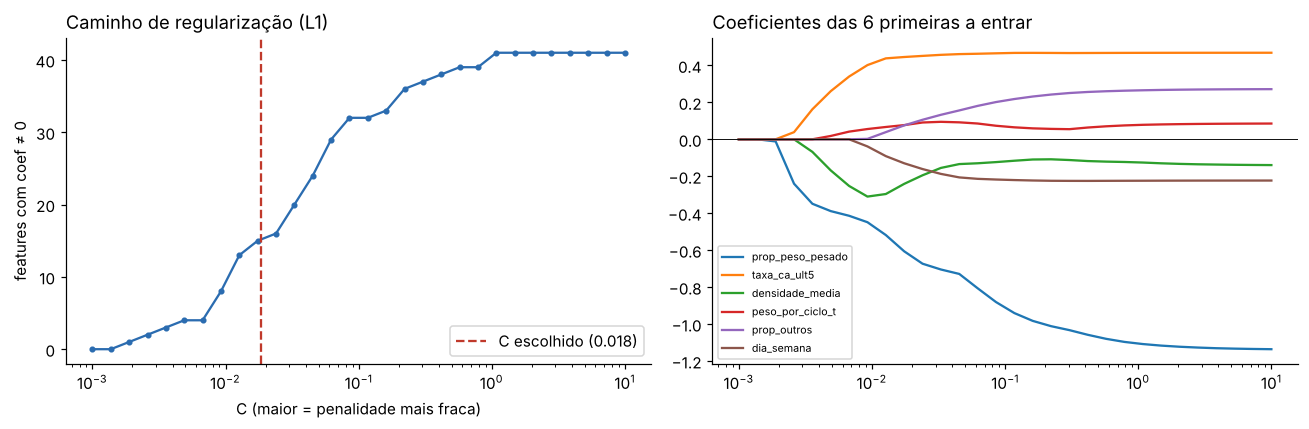

In [15]:
def regra_1ep(lcv):
    notas = lcv.scores_[1]
    media, ep = notas.mean(0), notas.std(0) / np.sqrt(notas.shape[0])
    if notas.ndim == 3:                                   # elastic net: (dobras, Cs, l1_ratios)
        media, ep = media[:, 0], ep[:, 0]
    i = media.argmax()
    return lcv.Cs_[np.where(media >= media[i] - ep[i])[0].min()]

def selecao_penalizada(penalty, **kw):
    lcv = Pipeline([("imputar", SimpleImputer(strategy="median")), ("padronizar", StandardScaler()),
                    ("modelo", LogisticRegressionCV(Cs=np.logspace(-3, 1, 20), penalty=penalty, solver="saga",
                                                    cv=splits, scoring="average_precision",
                                                    class_weight="balanced", max_iter=5000,
                                                    random_state=SEED, **kw))]).fit(X_tr, y_tr)
    C = regra_1ep(lcv.named_steps["modelo"])
    extra = {"l1_ratio": kw["l1_ratios"][0]} if "l1_ratios" in kw else {}
    final = logreg(penalty=penalty, solver="saga", C=C, **extra).fit(X_tr, y_tr)
    return C, pd.Series(final.named_steps["modelo"].coef_[0], index=candidatas_finais)

C_l1, coef_l1 = selecao_penalizada("l1")
C_en, coef_en = selecao_penalizada("elasticnet", l1_ratios=[0.5])
sel_l1, sel_en = list(coef_l1[coef_l1 != 0].index), list(coef_en[coef_en != 0].index)
print(f"L1:          C = {C_l1:.4f} -> mantém {len(sel_l1)} de {len(candidatas_finais)}")
print(f"Elastic Net: C = {C_en:.4f} -> mantém {len(sel_en)} de {len(candidatas_finais)}")
print("\nCoeficientes L1 (padronizados; + aumenta o risco de carga alta):")
print(coef_l1[coef_l1 != 0].sort_values(key=abs, ascending=False).round(3).to_string())

# caminho de regularização (L1)
Cs = np.logspace(-3, 1, 30)
caminho = pd.DataFrame({C: logreg(penalty="l1", solver="saga", C=C).fit(X_tr, y_tr).named_steps["modelo"].coef_[0]
                        for C in Cs}, index=candidatas_finais).T
entrada = (caminho != 0).idxmax().where((caminho != 0).any()).sort_values()
print("\nOrdem de entrada no caminho do L1 (primeiras 12):", list(entrada.index[:12]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(Cs, (caminho != 0).sum(axis=1), marker="o", ms=3, color=AZUL)
axes[0].axvline(C_l1, ls="--", color=VERMELHO, label=f"C escolhido ({C_l1:.3f})")
axes[0].set_xscale("log"); axes[0].set_xlabel("C (maior = penalidade mais fraca)"); axes[0].set_ylabel("features com coef ≠ 0")
axes[0].set_title("Caminho de regularização (L1)", loc="left"); axes[0].legend()
for c in entrada.index[:6]:
    axes[1].plot(Cs, caminho[c], label=c)
axes[1].set_xscale("log"); axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_title("Coeficientes das 6 primeiras a entrar", loc="left"); axes[1].legend(fontsize=7)
salvar("02_caminho_regularizacao")

Permutação na validação — queda claramente > 0 (média − 2·erro-padrão > 0): ['taxa_ca_ult5', 'prop_peso_pesado', 'taxa_ca_ult10', 'dia_semana', 'peso_por_ciclo_t', 'prop_leve', 'taxa_ca_ult20', 'peso_base_30pct_t', 'prop_leve_topo', 'densidade_media', 'hhi_materiais', 'prop_OXIC', 'peso_topo_30pct_t', 'intervalo_medio_min', 'peso_leve_topo_t', 'peso_medio_camada_t', 'turno_A', 'peso_max_camada_t', 'prop_ESPR', 'prop_PACB', 'fim_de_semana', 'turno_B', 'mudou_composicao', 'prop_CAFO', 'topo_leve']


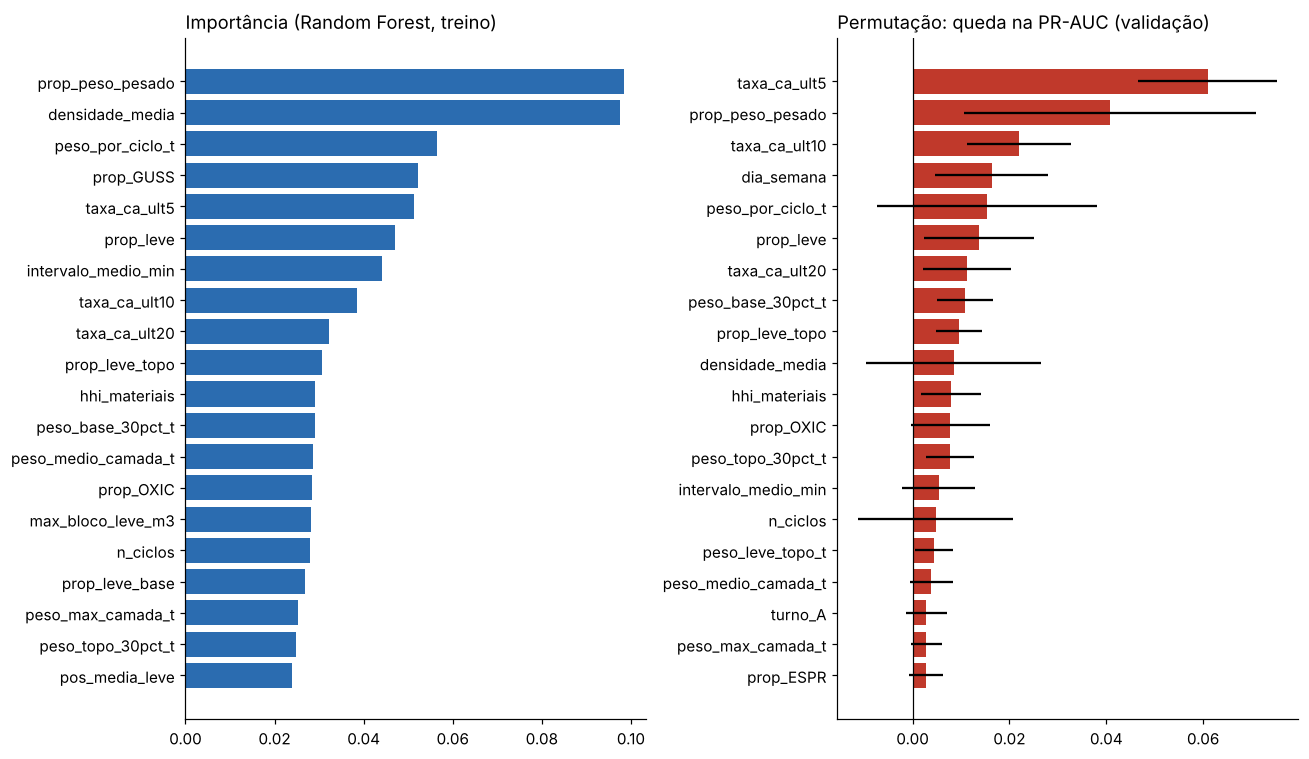

In [16]:
rf = floresta().fit(X_tr, y_tr)
imp_rf = pd.Series(rf.named_steps["modelo"].feature_importances_, index=candidatas_finais).sort_values(ascending=False)
perm = permutation_importance(rf, X_va, y_va, scoring="average_precision", n_repeats=30, random_state=SEED, n_jobs=-1)
imp_perm = pd.DataFrame({"media": perm.importances_mean, "dp": perm.importances_std},
                        index=candidatas_finais).sort_values("media", ascending=False)
sel_perm = list(imp_perm[(imp_perm["media"] - 2 * imp_perm["dp"] / np.sqrt(30)) > 0].index)
print("Permutação na validação — queda claramente > 0 (média − 2·erro-padrão > 0):", sel_perm)

fig, axes = plt.subplots(1, 2, figsize=(12, 7))
t = imp_rf.head(20)
axes[0].barh(t.index[::-1], t[::-1], color=AZUL); axes[0].set_title("Importância (Random Forest, treino)", loc="left")
t = imp_perm.head(20)
axes[1].barh(t.index[::-1], t["media"][::-1], xerr=t["dp"][::-1], color=VERMELHO)
axes[1].axvline(0, color="k", lw=0.8); axes[1].set_title("Permutação: queda na PR-AUC (validação)", loc="left")
salvar("03_importancia_e_permutacao")

## 8. Wrapper: RFE com validação cruzada (slides 22–23, Guia §8.2)

Treina, tira a coluna menos importante, repete. A validação cruzada (no treino, agrupada por
corrida) mostra quantas colunas compensa manter; usamos de novo a regra de 1 erro-padrão.
Para checar estabilidade (Guia §8.2), rodamos também com regressão logística e comparamos.

RFE (Random Forest): melhor média com 35; regra 1 EP -> 35: [np.str_('densidade_media'), np.str_('peso_max_camada_t'), np.str_('peso_medio_camada_t'), np.str_('prop_leve'), np.str_('prop_peso_pesado'), np.str_('hhi_materiais'), np.str_('prop_118441'), np.str_('prop_CAVA'), np.str_('prop_ESPR'), np.str_('prop_FOFO'), np.str_('prop_GUSS'), np.str_('prop_OXIC'), np.str_('prop_PACB'), np.str_('prop_PAEP'), np.str_('prop_RECA'), np.str_('prop_outros'), np.str_('max_bloco_leve_m3'), np.str_('n_ciclos'), np.str_('n_ciclos_LPM'), np.str_('peso_topo_30pct_t'), np.str_('peso_base_30pct_t'), np.str_('peso_leve_topo_t'), np.str_('prop_leve_topo'), np.str_('prop_leve_base'), np.str_('pos_media_pesado'), np.str_('pos_media_leve'), np.str_('intervalo_medio_min'), np.str_('hora'), np.str_('turno_A'), np.str_('dia_semana'), np.str_('fim_de_semana'), np.str_('peso_por_ciclo_t'), np.str_('taxa_ca_ult5'), np.str_('taxa_ca_ult10'), np.str_('taxa_ca_ult20')]
RFE (Reg. logística): regra 1 EP -> 2: [np.str_('

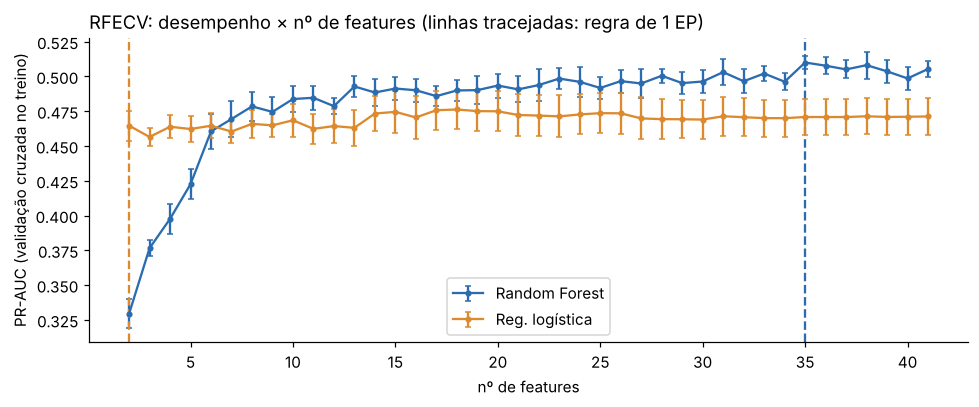

In [17]:
X_tr_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_tr), columns=candidatas_finais)
X_tr_pad = pd.DataFrame(StandardScaler().fit_transform(X_tr_imp), columns=candidatas_finais)

def rfe_1ep(estimador, X):
    r = RFECV(estimador, step=1, cv=splits, scoring="average_precision", min_features_to_select=2, n_jobs=1).fit(X, y_tr)
    res = pd.DataFrame({k: r.cv_results_[k] for k in ["n_features", "mean_test_score", "std_test_score"]})
    res["ep"] = res["std_test_score"] / np.sqrt(len(splits))
    best = res.loc[res["mean_test_score"].idxmax()]
    n = int(res.loc[res["mean_test_score"] >= best["mean_test_score"] - best["ep"], "n_features"].min())
    sup = RFE(estimador, n_features_to_select=n, step=1).fit(X, y_tr).support_
    return list(np.array(candidatas_finais)[sup]), res, n, r.n_features_

rf_rfe = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=SEED)
sel_rfe, res_rfe, n_rfe, n_rfe_max = rfe_1ep(rf_rfe, X_tr_imp)
sel_rfe_lr, res_rfe_lr, n_rfe_lr, _ = rfe_1ep(LogisticRegression(max_iter=5000, class_weight="balanced"), X_tr_pad)
print(f"RFE (Random Forest): melhor média com {n_rfe_max}; regra 1 EP -> {n_rfe}: {sel_rfe}")
print(f"RFE (Reg. logística): regra 1 EP -> {n_rfe_lr}: {sel_rfe_lr}")
print("Em comum:", sorted(set(sel_rfe) & set(sel_rfe_lr)))

fig, ax = plt.subplots(figsize=(9, 3.8))
for res, n, nome, cor in [(res_rfe, n_rfe, "Random Forest", AZUL), (res_rfe_lr, n_rfe_lr, "Reg. logística", LARANJA)]:
    ax.errorbar(res["n_features"], res["mean_test_score"], yerr=res["ep"], marker="o", ms=3, capsize=2, color=cor, label=nome)
    ax.axvline(n, ls="--", color=cor)
ax.set_xlabel("nº de features"); ax.set_ylabel("PR-AUC (validação cruzada no treino)")
ax.set_title("RFECV: desempenho × nº de features (linhas tracejadas: regra de 1 EP)", loc="left"); ax.legend()
salvar("04_rfecv")

## 9. Competir contra colunas de mentira — Boruta (slide 27)

Para cada coluna criamos uma cópia embaralhada (ruído puro). A floresta treina com reais +
falsas; uma coluna real ganha um ponto quando sua importância supera a **melhor** falsa.
Repetimos 30 vezes e fica quem vence mais que o acaso (teste binomial). Feito à mão, sem o
pacote `boruta`.

In [18]:
rng = np.random.default_rng(SEED)
N_ROD = 30
vitorias = pd.Series(0, index=candidatas_finais)
for i in range(N_ROD):
    sombra = X_tr_imp.apply(lambda s: rng.permutation(s.values)).add_prefix("sombra_")
    X_comb = pd.concat([X_tr_imp, sombra], axis=1)
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                               n_jobs=-1, random_state=SEED + i).fit(X_comb, y_tr)
    imp = pd.Series(m.feature_importances_, index=X_comb.columns)
    vitorias += (imp[candidatas_finais] > imp[sombra.columns].max()).astype(int)
p_boruta = vitorias.apply(lambda k: binomtest(int(k), N_ROD, 0.5, alternative="greater").pvalue)
sel_boruta = list(vitorias[p_boruta < 0.05].index)
print("Confirmadas pelo Boruta:", sel_boruta)

Confirmadas pelo Boruta: ['densidade_media', 'prop_leve', 'prop_peso_pesado', 'hhi_materiais', 'prop_GUSS', 'prop_OXIC', 'max_bloco_leve_m3', 'n_ciclos', 'peso_topo_30pct_t', 'peso_base_30pct_t', 'prop_leve_topo', 'prop_leve_base', 'intervalo_medio_min', 'peso_por_ciclo_t', 'taxa_ca_ult5', 'taxa_ca_ult10', 'taxa_ca_ult20']


## 10. Votação, estabilidade e quantas features ficam

**Votação (slide 32: não confiar num método só; Guia §8.3: "features que aparecem em todos os
métodos são candidatas fortes").** Seis votos: filtro, RFE, L1, Elastic Net, permutação e Boruta.

**Estabilidade:** repetimos o L1 (mesmo C) em 50 subamostras de metade das corridas do treino.
Uma feature escolhida em 90% das vezes é robusta; em 30%, é sorte.

**Quantas features (Guia §9.3):** ordenamos as features por votos (desempate: vitórias no
Boruta) e adicionamos uma a uma, medindo a PR-AUC na **validação** com a Random Forest. O
"cotovelo" é o menor nº de features cuja curva (suavizada) chega a 98% do máximo.

In [19]:
votos = pd.DataFrame(index=candidatas_finais)
votos["filtro"] = filtro["voto_filtro"].reindex(candidatas_finais)
votos["RFE"] = votos.index.isin(sel_rfe)
votos["L1"] = votos.index.isin(sel_l1)
votos["ElasticNet"] = votos.index.isin(sel_en)
votos["permutacao"] = votos.index.isin(sel_perm)
votos["boruta"] = votos.index.isin(sel_boruta)
votos = votos.astype(int)
votos["total"] = votos.sum(axis=1)

# estabilidade do L1
corridas_tr = treino["cd_corrida"].unique()
freq = pd.Series(0.0, index=candidatas_finais)
for i in range(50):
    sub = np.random.default_rng(SEED + i).choice(corridas_tr, size=len(corridas_tr) // 2, replace=False)
    msk = treino["cd_corrida"].isin(sub)
    coef = logreg(penalty="l1", solver="saga", C=C_l1).fit(X_tr[msk], y_tr[msk]).named_steps["modelo"].coef_[0]
    freq += (coef != 0)
votos["estabilidade_L1"] = (freq / 50).round(2)
votos["vitorias_boruta"] = vitorias
votos["corr"] = filtro["corr"].reindex(candidatas_finais).round(3)
votos = votos.sort_values(["total", "vitorias_boruta"], ascending=False)
print(votos.to_string())

                     filtro  RFE  L1  ElasticNet  permutacao  boruta  total  estabilidade_L1  vitorias_boruta   corr
densidade_media           1    1   1           1           1       1      6             1.00               30 -0.295
prop_peso_pesado          1    1   1           1           1       1      6             1.00               30 -0.317
peso_por_ciclo_t          1    1   1           1           1       1      6             0.78               30  0.292
taxa_ca_ult5              1    1   1           1           1       1      6             1.00               30  0.260
taxa_ca_ult10             1    1   1           1           1       1      6             0.46               30  0.233
prop_PACB                 1    1   1           1           1       0      5             0.64                0  0.128
dia_semana                1    1   1           1           1       0      5             0.64                0 -0.075
prop_leve                 1    1   0           0           1    

Cotovelo: 6 features -> ['densidade_media', 'prop_peso_pesado', 'peso_por_ciclo_t', 'taxa_ca_ult5', 'taxa_ca_ult10', 'prop_PACB']


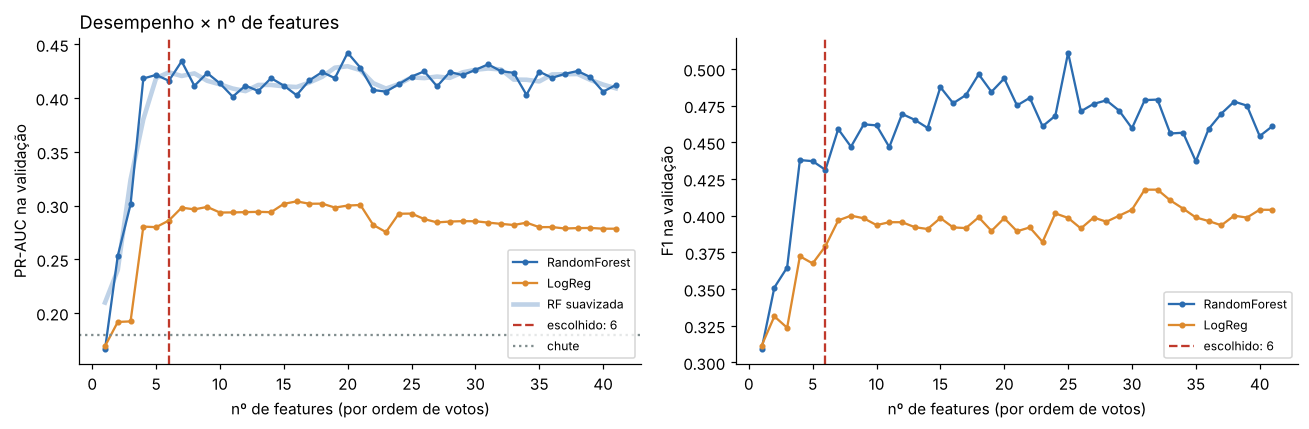

In [20]:
ranking = list(votos.index)
curva = []
for k in range(1, len(ranking) + 1):
    cols = ranking[:k]
    linha = {"k": k}
    for alg_nome, fabrica in ALGORITMOS.items():
        p = fabrica(200).fit(treino[cols], y_tr).predict_proba(valid[cols])[:, 1] if alg_nome == "RandomForest" \
            else fabrica().fit(treino[cols], y_tr).predict_proba(valid[cols])[:, 1]
        linha[f"{alg_nome}_PR-AUC"] = average_precision_score(y_va, p)
        linha[f"{alg_nome}_F1"] = f1_score(y_va, p >= melhor_limiar(y_va, p))
    curva.append(linha)
curva = pd.DataFrame(curva).set_index("k")
suave = curva["RandomForest_PR-AUC"].rolling(3, center=True, min_periods=1).mean()
k_final = int(suave[suave >= 0.98 * suave.max()].index.min())
sel_final = ranking[:k_final]
print(f"Cotovelo: {k_final} features ->", sel_final)
curva.assign(feature_adicionada=ranking, RF_suavizada=suave).to_csv(PASTA_SAIDA / "curva_n_features.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for alg_nome, cor in [("RandomForest", AZUL), ("LogReg", LARANJA)]:
    axes[0].plot(curva.index, curva[f"{alg_nome}_PR-AUC"], marker="o", ms=3, color=cor, label=alg_nome)
    axes[1].plot(curva.index, curva[f"{alg_nome}_F1"], marker="o", ms=3, color=cor, label=alg_nome)
axes[0].plot(suave.index, suave, color=AZUL, lw=3, alpha=0.3, label="RF suavizada")
for ax, met in [(axes[0], "PR-AUC"), (axes[1], "F1")]:
    ax.axvline(k_final, ls="--", color=VERMELHO, label=f"escolhido: {k_final}")
    if met == "PR-AUC":
        ax.axhline(y_va.mean(), color=CINZA, ls=":", label="chute")
    ax.set_xlabel("nº de features (por ordem de votos)"); ax.set_ylabel(f"{met} na validação"); ax.legend(fontsize=8)
axes[0].set_title("Desempenho × nº de features", loc="left")
salvar("05_curva_desempenho_n_features")

## 11. Comparar os conjuntos na validação (Guia §9.2)

Mesmos dois algoritmos para todos. O limiar de recall/precisão/F1 é o de melhor F1 na própria
validação (por isso essas três ficam um pouco otimistas aqui; no teste, o limiar vem da
validação). Também testamos:
- o **baseline mínimo "só volume"** (Guia de Modelagem §3.1, passo 6: todas × selecionadas × só volume);
- o **conjunto básico** sugerido pelo Guia (`peso_t_total`, `volume_m3_total`, `num_materiais`);
- o conjunto final **sem as features de ciclo** (as features de ordem agregam? Guia §5);
- o conjunto final **com `carga_alta_c1`** (só faz sentido se a EVCOMX confirmar o timing).

In [21]:
FEAT_CICLO = [c for c in candidatas_finais if c.startswith(("n_ciclos", "n_blocos", "max_bloco", "peso_por_ciclo"))]
FEAT_TEMPO = [c for c in candidatas_finais if c in ["hora", "turno_A", "turno_B", "dia_semana", "fim_de_semana",
                                                     "tempo_montagem_min", "intervalo_medio_min"]]
FEAT_HIST = [c for c in candidatas_finais if c.startswith("taxa_ca_ult")]
conjuntos = {
    "só volume (baseline mínimo, Guia de Modelagem §3.1)": ["volume_m3_total"],
    "básico do Guia (3)": ["peso_t_total", "volume_m3_total", "num_materiais"],
    "filtro": list(votos.index[votos.filtro == 1]),
    "wrapper: RFE": sel_rfe,
    "embedded: L1": sel_l1,
    "embedded: Elastic Net": sel_en,
    "Boruta": sel_boruta,
    "consenso (>= 4 votos)": list(votos.index[votos.total >= 4]),
    f"FINAL (cotovelo, {k_final})": sel_final,
    "final sem features de ciclo": [c for c in sel_final if c not in FEAT_CICLO],
    "final sem features de tempo": [c for c in sel_final if c not in FEAT_TEMPO],
    "final sem histórico recente": [c for c in sel_final if c not in FEAT_HIST],
    "final + carga_alta_c1": sel_final + ["carga_alta_c1"],
}
for nome, cols in conjuntos.items():
    if len(cols):
        comparacao.append(avaliar_validacao(cols, nome))
tab_valid = pd.DataFrame(comparacao).set_index("conjunto")
tab_valid.round(3)

,n,LogReg_PR-AUC,LogReg_ROC-AUC,LogReg_F1,LogReg_recall,LogReg_precisao,RandomForest_PR-AUC,RandomForest_ROC-AUC,RandomForest_F1,RandomForest_recall,RandomForest_precisao
conjunto,,,,,,,,,,,
todas as candidatas,84,0.344,0.713,0.426,0.565,0.342,0.397,0.744,0.465,0.511,0.427
após multicolinearidade,41,0.278,0.680,0.404,0.663,0.290,0.413,0.750,0.472,0.641,0.373
"só volume (baseline mínimo, Guia de Modelagem §3.1)",1,0.198,0.573,0.338,0.717,0.221,0.187,0.482,0.310,0.826,0.190
básico do Guia (3),3,0.164,0.480,0.311,0.978,0.185,0.241,0.588,0.336,0.815,0.211
filtro,24,0.279,0.679,0.388,0.848,0.252,0.408,0.749,0.470,0.630,0.374
wrapper: RFE,35,0.284,0.686,0.403,0.641,0.294,0.427,0.755,0.473,0.609,0.386
embedded: L1,15,0.273,0.674,0.389,0.522,0.310,0.410,0.718,0.420,0.598,0.324
embedded: Elastic Net,8,0.297,0.685,0.395,0.543,0.311,0.409,0.730,0.451,0.620,0.354
Boruta,17,0.278,0.658,0.368,0.815,0.237,0.408,0.745,0.462,0.565,0.391


## 11b. Features sugeridas pelo Guia de Modelagem, testadas à parte

O Guia de Modelagem (§2.2 C) sugere três features de estrutura que ainda não estavam entre as
candidatas:
- **`violacao_fundo_topo`**: o cestão não começa **ou** não termina com leve (a regra
  leve–pesado–leve do Guia; a nossa `violacao_regra` olha só pesado no fundo/topo);
- **`colchao_topo_m3`**: volume do último bloco de camadas, se ele for de leve (o "colchão" do topo);
- **`prop_vol_centro`**: proporção do volume nas camadas centrais (fora dos 30% de baixo e de cima).

**Por que à parte, e não como candidatas?** Testamos incluí-las na votação (rodada única,
feita ainda com o corte antigo de peso zero e registrada no README): nenhuma passou de 4 votos,
mas a presença delas mudou a ordem da multicolinearidade e do RFE, e o cotovelo caiu de 9 para as
**5 features com 6 votos** (que continuam sendo as 5 primeiras do conjunto final). Ou seja, elas não entram por mérito próprio e só
perturbariam uma seleção já feita. Aqui medimos o que acrescentam **ao conjunto final**, com o
treino e a validação de sempre. A curva `curva_n_features.csv` mostra a diferença entre as 5 primeiras e o conjunto final.

In [22]:
ultimo_bloco = blocos.groupby(chave).tail(1).set_index(chave)
centro = ~topo30 & ~base30
extra = pd.DataFrame({
    "violacao_regra": ((primeira == "Pesado") | (ultima == "Pesado")).astype(int),
    "violacao_fundo_topo": ((primeira != "Leve") | (ultima != "Leve")).astype(int),
    "colchao_topo_m3": ultimo_bloco["volume_m3"].where(ultimo_bloco["classe"] == "Leve", 0),
    "prop_vol_centro": cam[centro].groupby(chave)["volume_m3"].sum().reindex(primeira.index).fillna(0)
                       / g["volume_m3"].sum(),
}).reset_index()
EXTRA = ["violacao_fundo_topo", "colchao_topo_m3", "prop_vol_centro"]
for parte in (treino, valid, teste):
    parte.drop(columns=[c for c in extra.columns if c not in chave and c in parte], inplace=True)
treino, valid, teste = [p.merge(extra, on=chave, how="left") for p in (treino, valid, teste)]
linhas_extra = []
for c in EXTRA:
    x = treino[c]
    _, p_mw = mannwhitneyu(x[y_tr == 0], x[y_tr == 1])
    linhas_extra.append({"feature": c, "corr_treino": pointbiserialr(y_tr, x)[0], "p_mannwhitney": p_mw,
                         "media_sem_CA": x[y_tr == 0].mean(), "media_com_CA": x[y_tr == 1].mean(),
                         **{f"final+{c}: {k}": v for k, v in avaliar_validacao(sel_final + [c], c).items()
                            if k.endswith("PR-AUC")}})
tab_extra = pd.DataFrame(linhas_extra).set_index("feature")
tab_extra.to_csv(PASTA_SAIDA / "features_guia_modelagem_avaliacao.csv")
ref = tab_valid.loc[f"FINAL (cotovelo, {k_final})"]
print(f"Referência, conjunto final: PR-AUC validação RF {ref['RandomForest_PR-AUC']:.3f} | LogReg {ref['LogReg_PR-AUC']:.3f}")
print("Taxa de carga alta no treino:", round(y_tr.mean(), 3), "| com violacao_fundo_topo = 1:",
      round(y_tr[treino.violacao_fundo_topo == 1].mean(), 3), "| = 0:", round(y_tr[treino.violacao_fundo_topo == 0].mean(), 3))
tab_extra.round(3)

Referência, conjunto final: PR-AUC validação RF 0.420 | LogReg 0.286
Taxa de carga alta no treino: 0.159 | com violacao_fundo_topo = 1: 0.124 | = 0: 0.166


,corr_treino,p_mannwhitney,media_sem_CA,media_com_CA,final+violacao_fundo_topo: LogReg_PR-AUC,final+violacao_fundo_topo: RandomForest_PR-AUC,final+colchao_topo_m3: LogReg_PR-AUC,final+colchao_topo_m3: RandomForest_PR-AUC,final+prop_vol_centro: LogReg_PR-AUC,final+prop_vol_centro: RandomForest_PR-AUC
feature,,,,,,,,,,
violacao_fundo_topo,-0.044,0.029,0.184,0.138,0.279,0.421,NaN,NaN,NaN,NaN
colchao_topo_m3,0.113,0.001,7.714,9.156,NaN,NaN,0.28,0.402,NaN,NaN
prop_vol_centro,-0.078,0.001,0.336,0.315,NaN,NaN,NaN,NaN,0.286,0.429


## 12. Conferência no TESTE — uma única vez (slide 30, Guia §9)

Treina no treino, escolhe o limiar na validação (melhor F1) e aplica no teste. Métricas do
Guia: acurácia, recall, precisão, F1, ROC-AUC e PR-AUC.

In [23]:
final = []
for nome, cols in [("todas as candidatas", candidatas), ("básico do Guia (3)", conjuntos["básico do Guia (3)"]),
                   (f"FINAL ({k_final})", sel_final)]:
    for alg_nome, fabrica in ALGORITMOS.items():
        modelo = fabrica().fit(treino[cols], y_tr)
        lim = melhor_limiar(y_va, modelo.predict_proba(valid[cols])[:, 1])
        p = modelo.predict_proba(teste[cols])[:, 1]
        prev = p >= lim
        final.append({"conjunto": nome, "algoritmo": alg_nome, "n": len(cols), "limiar": lim,
                      "acuracia": accuracy_score(y_te, prev), "recall": recall_score(y_te, prev),
                      "precisao": precision_score(y_te, prev, zero_division=0), "F1": f1_score(y_te, prev),
                      "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p)})
        if nome.startswith("FINAL") and alg_nome == "RandomForest":
            matriz = pd.DataFrame(confusion_matrix(y_te, prev), index=["real: normal", "real: carga alta"],
                                  columns=["previsto: normal", "previsto: carga alta"])
tab_teste = pd.DataFrame(final)
print(f"Referência no teste: PR-AUC de um chute = {y_te.mean():.3f}; "
      f"acurácia de quem sempre diz 'normal' = {1 - y_te.mean():.3f}")
print("\nMatriz de confusão (FINAL, Random Forest):\n", matriz)
tab_teste.round(3)

Referência no teste: PR-AUC de um chute = 0.146; acurácia de quem sempre diz 'normal' = 0.854

Matriz de confusão (FINAL, Random Forest):
                   previsto: normal  previsto: carga alta
real: normal                   322                   118
real: carga alta                23                    52


,conjunto,algoritmo,n,limiar,acuracia,recall,precisao,F1,ROC-AUC,PR-AUC
0,todas as candidatas,LogReg,84,0.77,0.808,0.547,0.387,0.453,0.754,0.413
1,todas as candidatas,RandomForest,84,0.49,0.790,0.467,0.340,0.393,0.744,0.353
2,básico do Guia (3),LogReg,3,0.34,0.181,0.987,0.149,0.260,0.608,0.194
3,básico do Guia (3),RandomForest,3,0.30,0.361,0.853,0.168,0.280,0.619,0.209
4,FINAL (6),LogReg,6,0.54,0.583,0.880,0.243,0.380,0.774,0.420
5,FINAL (6),RandomForest,6,0.47,0.726,0.693,0.306,0.424,0.771,0.383


## 13. Por que o desempenho cai fora do treino? Mudança de regime em maio/2026

O treino vai até 25/04/2026; validação e teste caem inteiros num período em que o processo
mudou. Mês a mês:

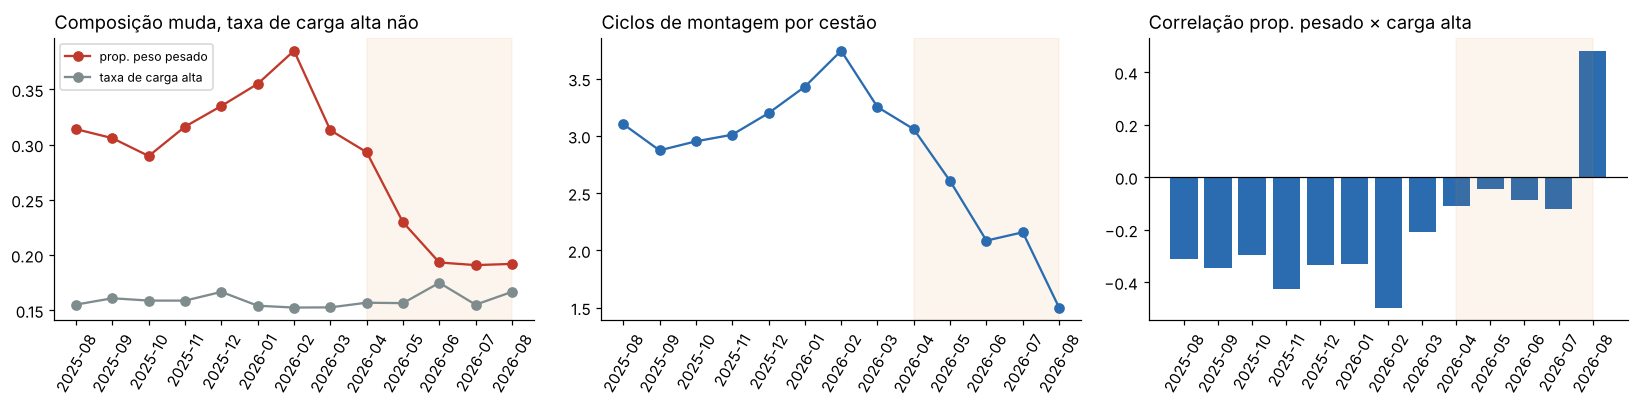

,cestoes,taxa_carga_alta,densidade_media,prop_peso_pesado,ciclos_medios,corr_pesado_x_alvo
mes,,,,,,
2025-08,116,0.155,0.849,0.314,3.103,-0.313
2025-09,404,0.161,0.866,0.306,2.874,-0.345
2025-10,359,0.159,0.846,0.290,2.953,-0.297
2025-11,378,0.159,0.847,0.316,3.011,-0.426
2025-12,216,0.167,0.866,0.335,3.199,-0.334
2026-01,279,0.154,0.889,0.355,3.430,-0.332
2026-02,223,0.152,0.887,0.385,3.744,-0.496
2026-03,190,0.153,0.841,0.313,3.253,-0.209
2026-04,357,0.157,0.856,0.293,3.059,-0.111


In [24]:
d = df.copy()
d["mes"] = d["inicio"].dt.strftime("%Y-%m")
mensal = d.groupby("mes").agg(cestoes=("carga_alta", "size"), taxa_carga_alta=("carga_alta", "mean"),
                              densidade_media=("densidade_media", "mean"),
                              prop_peso_pesado=("prop_peso_pesado", "mean"), ciclos_medios=("n_ciclos", "mean"),
                              corr_pesado_x_alvo=("prop_peso_pesado", lambda s: s.corr(d.loc[s.index, "carga_alta"])))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(mensal.index, mensal["prop_peso_pesado"], marker="o", color=VERMELHO, label="prop. peso pesado")
axes[0].plot(mensal.index, mensal["taxa_carga_alta"], marker="o", color=CINZA, label="taxa de carga alta")
axes[0].set_title("Composição muda, taxa de carga alta não", loc="left"); axes[0].legend(fontsize=8)
axes[1].plot(mensal.index, mensal["ciclos_medios"], marker="o", color=AZUL)
axes[1].set_title("Ciclos de montagem por cestão", loc="left")
axes[2].bar(mensal.index, mensal["corr_pesado_x_alvo"], color=AZUL); axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_title("Correlação prop. pesado × carga alta", loc="left")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
    ax.axvspan("2026-04", "2026-08", color=LARANJA, alpha=0.08)
salvar("06_mudanca_de_regime")
mensal.round(3)

## 14. Respostas às perguntas do Guia §1.3

(Os números abaixo são calculados; a interpretação está no README da pasta.)

In [25]:
rf_final = floresta().fit(treino[sel_final], y_tr)
perm_final = permutation_importance(rf_final, valid[sel_final], y_va, scoring="average_precision",
                                    n_repeats=30, random_state=SEED, n_jobs=-1)
imp_final = pd.Series(perm_final.importances_mean, index=sel_final).sort_values(ascending=False)
print("1) Top 5 features do conjunto final (permutação na validação) e correlação com carga alta:")
for c in imp_final.index[:5]:
    print(f"   {c:22s} queda PR-AUC {imp_final[c]:.3f} | corr {filtro.loc[c, 'corr'] if c in filtro.index else np.nan:+.3f}")
print("\n2) Volume x peso — correlação com carga alta no treino:")
for c in ["volume_m3_total", "peso_t_total", "densidade_media", "prop_peso_pesado"]:
    print(f"   {c:18s} {filtro.loc[c, 'corr']:+.3f}")
print("   PR-AUC na validação (RF) só com volume:", round(avaliar_validacao(["volume_m3_total"], "x")["RandomForest_PR-AUC"], 3),
      "| só com peso:", round(avaliar_validacao(["peso_t_total"], "x")["RandomForest_PR-AUC"], 3))
print("\n3) Features de ordem/ciclo agregam? PR-AUC validação (RF / LogReg):")
for nome in [f"FINAL (cotovelo, {k_final})", "final sem features de ciclo"]:
    print(f"   {nome:32s} {tab_valid.loc[nome, 'RandomForest_PR-AUC']:.3f} / {tab_valid.loc[nome, 'LogReg_PR-AUC']:.3f}")
print("\n4) Melhor método de seleção na validação (RF PR-AUC):")
print(tab_valid["RandomForest_PR-AUC"].sort_values(ascending=False).round(3).to_string())
print(f"\n5) Quantas features: cotovelo em {k_final} (de {len(candidatas)} candidatas).")

1) Top 5 features do conjunto final (permutação na validação) e correlação com carga alta:
   prop_peso_pesado       queda PR-AUC 0.095 | corr -0.317
   taxa_ca_ult5           queda PR-AUC 0.091 | corr +0.260
   peso_por_ciclo_t       queda PR-AUC 0.061 | corr +0.292
   taxa_ca_ult10          queda PR-AUC 0.042 | corr +0.233
   densidade_media        queda PR-AUC 0.037 | corr -0.295

2) Volume x peso — correlação com carga alta no treino:
   volume_m3_total    -0.037
   peso_t_total       -0.188
   densidade_media    -0.295
   prop_peso_pesado   -0.317
   PR-AUC na validação (RF) só com volume: 0.187 | só com peso: 0.215

3) Features de ordem/ciclo agregam? PR-AUC validação (RF / LogReg):
   FINAL (cotovelo, 6)              0.420 / 0.286
   final sem features de ciclo      0.426 / 0.281

4) Melhor método de seleção na validação (RF PR-AUC):
conjunto
final + carga_alta_c1                                  0.434
consenso (>= 4 votos)                                  0.428
wrapper: RFE    

## 15. Arquivos para a modelagem

- `dataset_modelagem_fs.csv`: conjunto FINAL + `carga_alta` + metadados (`cd_corrida`,
  `nu_carregamento`, `conjunto` com o split 70/15/15, `inicio`). **`inicio` não é feature.**
- `dataset_features_completo.csv`: todas as candidatas (para a seleção de algoritmos testar
  outros conjuntos).
- `votos_feature_selection.csv`: votos de cada método, estabilidade e correlação.
- `tabela_features_finais.csv`: o entregável do Guia de Modelagem (§3.2): como cada feature final
  é calculada, por que entra e quando está disponível.
- `curva_n_features.csv`: PR-AUC na validação conforme o nº de features (passo 6 do Guia).
- `features_guia_modelagem.csv`: as três features da seção 11b e `violacao_regra`, por cestão
  (usadas na validação de domínio da verificação).
- `graficos/`: figuras para a apresentação.

In [26]:
meta = ["cd_corrida", "nu_carregamento", "conjunto", "inicio"]
df[meta + sel_final + ["carga_alta"]].to_csv(PASTA_SAIDA / "dataset_modelagem_fs.csv", index=False)
df[meta + candidatas + ["carga_alta_c1", "carga_alta"]].to_csv(PASTA_SAIDA / "dataset_features_completo.csv", index=False)
votos.to_csv(PASTA_SAIDA / "votos_feature_selection.csv")
extra.to_csv(PASTA_SAIDA / "features_guia_modelagem.csv", index=False)

# Entregável do Guia de Modelagem (§3.2): como cada feature final é calculada, por que entra e
# quando está disponível no processo.
DESCRICAO = {
    "densidade_media": ("peso total ÷ volume estimado do cestão (volume = Σ peso da camada ÷ densidade do material)",
                        "cestão 'fofo' (pouca tonelada por m³) ocupa mais altura para o mesmo peso",
                        "após a montagem do cestão (pesagem das camadas)"),
    "prop_peso_pesado": ("peso das camadas de material pesado ÷ peso total",
                         "material pesado compacta a carga; pouco pesado = cestão volumoso",
                         "após a montagem do cestão"),
    "peso_por_ciclo_t": ("peso total ÷ nº de ciclos de montagem (ciclo = bloco de pesado)",
                         "ciclos 'grossos' = camadas pouco intercaladas, leve acumulado sem pesado em cima",
                         "após a montagem do cestão"),
    "taxa_ca_ult5": ("% de corridas com carga alta entre as 5 corridas anteriores (shift(1), nunca a atual)",
                     "estado recente do forno: carga alta puxa carga alta",
                     "quando a corrida anterior termina (CONFIRMAR com a EVCOMX se já é conhecido na montagem)"),
    "taxa_ca_ult10": ("% de corridas com carga alta entre as 10 corridas anteriores (shift(1))",
                      "mesma ideia, janela mais longa e mais estável",
                      "quando a corrida anterior termina (CONFIRMAR com a EVCOMX)"),
    "max_bloco_leve_m3": ("volume do maior bloco de camadas leves seguidas",
                          "bloco grande de leve sem pesado/misto intercalado ocupa muita altura",
                          "após a montagem do cestão"),
    "prop_leve_base": ("peso de leve nos 30% de camadas de baixo ÷ peso dessas camadas",
                       "muito leve no fundo = base fofa, carga mais alta",
                       "após a montagem do cestão"),
    "prop_PACB": ("peso do material PACB ÷ peso total",
                  "pacote de chaparia: material volumoso para o peso",
                  "após a montagem do cestão"),
    "prop_PAEP": ("peso do material PAEP ÷ peso total",
                  "pacote de estamparia: material volumoso para o peso",
                  "após a montagem do cestão"),
}
tabela_final = pd.DataFrame(
    [{"feature": c, "como_e_calculada": DESCRICAO.get(c, ("", "", ""))[0], "por_que_entra": DESCRICAO.get(c, ("", "", ""))[1],
      "quando_esta_disponivel": DESCRICAO.get(c, ("", "", ""))[2],
      "sinal (corr. no treino)": f"{filtro.loc[c, 'corr']:+.2f}", "votos (de 6)": int(votos.loc[c, "total"])}
     for c in sel_final])
faltando = [c for c in sel_final if c not in DESCRICAO]
if faltando:
    print("ATENÇÃO: o conjunto final mudou; descreva no dicionário DESCRICAO:", faltando)
tabela_final.to_csv(PASTA_SAIDA / "tabela_features_finais.csv", index=False)
print(tabela_final.to_string(index=False))
print("Conjunto final:", sel_final)
print("Salvos em", PASTA_SAIDA)

         feature                                                                           como_e_calculada                                                                    por_que_entra                                                                   quando_esta_disponivel sinal (corr. no treino)  votos (de 6)
 densidade_media peso total ÷ volume estimado do cestão (volume = Σ peso da camada ÷ densidade do material)        cestão 'fofo' (pouca tonelada por m³) ocupa mais altura para o mesmo peso                                          após a montagem do cestão (pesagem das camadas)                   -0.30             6
prop_peso_pesado                                           peso das camadas de material pesado ÷ peso total                 material pesado compacta a carga; pouco pesado = cestão volumoso                                                                após a montagem do cestão                   -0.32             6
peso_por_ciclo_t                            peso tot